# Laptop Price Prediction System – 10-Fold Cross Validation (Full Dataset)

## Setup: Running This Notebook on Google Colab

No installation is needed. Google Colab already has every library this notebook uses.

1. Go to **https://colab.research.google.com** and sign in with a Google account.
2. Click **File → Upload notebook** and choose this `.ipynb` file.
3. Click **Runtime → Run all**.
4. When **Step 2.1** runs, a **"Choose Files"** button appears below that cell. Click it and select the laptop dataset CSV (**`laptop_price.csv`**) from your computer. The notebook continues automatically after the upload.

> **Note:** Colab deletes uploaded files when the runtime is reset or disconnected. If you get a *"file not found"* error, run Step 2.1 again and re-upload the CSV.

---


## Introduction

##### **Definition** A regression ML task that predicts the price of a laptop from its specifications, such as the company, type, screen size, RAM, storage, processor, graphics card and operating system.
##### **Application** Online laptop marketplaces, price comparison websites, second-hand laptop valuation, retail stock pricing and helping buyers check whether a laptop is fairly priced.

### Aim of This Notebook

This notebook answers one question:

> **Which of 5 regression algorithms predicts laptop prices best, and how sure can we be about that answer?**

To answer it fairly we use **K-Fold Cross Validation** and compare the algorithms using **Root Mean Squared Error (RMSE)**.

The 5 algorithms (**Ridge Regression, Support Vector Regression, Extra Trees, AdaBoost and Hist Gradient Boosting**) were deliberately chosen so that none of them was used in the Car Price Prediction System (which used Linear Regression, KNN, Decision Tree, Random Forest and Gradient Boosting).

### What is K-Fold Cross Validation?

A single train/test split can be lucky or unlucky: the result depends on *which* laptops happened to land in the test set. K-Fold Cross Validation removes this luck:

1. Shuffle the data and split it into **K equal parts (folds)**.
2. Train the model on **K−1 folds** and test it on the **remaining fold**.
3. Repeat **K times**, so that **every fold is used as the test set exactly once**.
4. Report the **average** score over the K rounds (and the standard deviation, to show how much it varies).

With **K = 10** on the **full dataset (1,274 unique laptops)**, each test fold has about 127 laptops and each training set has about 1,147 laptops:

```
Round  1:  [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  2:  [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  3:  [train] | [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  4:  [train] | [train] | [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train]
Round  5:  [train] | [train] | [train] | [train] | [TEST ] | [train] | [train] | [train] | [train] | [train]
Round  6:  [train] | [train] | [train] | [train] | [train] | [TEST ] | [train] | [train] | [train] | [train]
Round  7:  [train] | [train] | [train] | [train] | [train] | [train] | [TEST ] | [train] | [train] | [train]
Round  8:  [train] | [train] | [train] | [train] | [train] | [train] | [train] | [TEST ] | [train] | [train]
Round  9:  [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [TEST ] | [train]
Round 10:  [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [TEST ]
```

Every laptop is used for testing **exactly once** and for training **K−1 times**.

### Evaluation Measure: Root Mean Squared Error (RMSE)

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

- $y_i$ = actual price, $\hat{y}_i$ = predicted price, $n$ = number of test laptops
- RMSE is in the **same unit as the output (the price)**, so it reads as *"on average, predictions are off by about X"*.
- **Lower RMSE = better model.** Because errors are squared, RMSE penalises **large mistakes** heavily.

## Input and Output

### Input (Features / Attributes)

| Feature | Description | Type | Possible Values |
|---|---|---|---|
| **Inches** | Screen size in inches | Numerical | 10.1 – 18.4 |
| **Ram** | RAM size in GB (from text such as `8GB`) | Numerical | 2 – 64 |
| **Weight** | Weight in kg (from text such as `1.37kg`) | Numerical | 0.69 – 4.7 |
| **SSD_GB** | Total SSD / flash storage in GB (extracted from `Memory`) | Numerical | 0 – 1024 |
| **HDD_GB** | Total HDD / hybrid storage in GB (extracted from `Memory`) | Numerical | 0 – 2048 |
| **Company** | Laptop brand | Categorical | Dell, Lenovo, HP, Asus, Acer, MSI, … (19 brands) |
| **TypeName** | Laptop category | Categorical | Notebook, Gaming, Ultrabook, 2 in 1 Convertible, Workstation, Netbook |
| **ScreenResolution** | Screen type and resolution | Categorical | Full HD 1920x1080, 1366x768, IPS Panel Full HD 1920x1080, … (40 values) |
| **Cpu** | Processor model | Categorical | Intel Core i5 7200U 2.5GHz, Intel Core i7 7700HQ 2.8GHz, … (118 values) |
| **Gpu** | Graphics card | Categorical | Intel HD Graphics 620, Nvidia GeForce GTX 1050, … (110 values) |
| **OpSys** | Operating system | Categorical | Windows 10, No OS, Linux, Windows 7, Chrome OS, macOS, … |

### Output (Prediction)

| Output Attribute | Description | Data Type |
|---|---|---|
| **Price** | Price of the laptop. The file does not state a currency; the values look like Indian Rupees. | Numerical |

## Developer & System Information

| **Attribute** | **Details** |
|---|---|
| **Developer Name** | [Your Name] |
| **Program Name** | `laptop_price_kfold_full_dataset_10fold` |
| **IDE** | Google Colab |
| **Programming Language** | Python 3 |
| **Libraries** | NumPy, Pandas, scikit-learn, Matplotlib, Pickle (built-in). Exact versions are printed in Step 1. |
| **Dataset** | `laptop_price.csv` (1,303 laptops, 11 attributes + 1 index column) |

### Table of Contents
- **Step 1:** Import Libraries
- **Step 2:** Load Sample Data
  - **Step 2.1:** Upload the Dataset (Google Colab)
  - **Step 2.2:** Read the Dataset
- **Step 3:** Understand and Pre-process Sample Data
  - **Step 3.1:** Understand Sample Data
  - **Step 3.2:** Pre-process Sample Data
- **Step 4:** Feature Extraction
- **Step 5:** Build the Pre-processing Pipeline
- **Step 6:** Define the 5 Regression Algorithms
- **Step 7:** Set Up 10-Fold Cross Validation
  - **Step 7.1:** Create the K-Fold Splitter
  - **Step 7.2:** Inspect the Folds
- **Step 8:** Run 10-Fold Cross Validation for All 5 Algorithms
- **Step 9:** Compare the Algorithms
  - **Step 9.1:** RMSE of Each Algorithm on Each Fold
  - **Step 9.2:** Summary Comparison Table
  - **Step 9.3:** Visual Comparison
  - **Step 9.4:** Observations
- **Step 10:** Train the Final Model
  - **Step 10.1:** Select the Best Algorithm
  - **Step 10.2:** Train the Best Algorithm on All the Data
  - **Step 10.3:** Save the Trained Model
- **Step 11:** Execute the Application Phase
  - **Step 11.1:** Take Input from User
  - **Step 11.2:** Convert User Input into Feature Vector
  - **Step 11.3:** Load the Saved Model
  - **Step 11.4:** Model Prediction
- **Step 12:** Execute the Feedback Phase
- **Conclusion**


# Code – Laptop Price Prediction System
## Step 1: Import Libraries

In [1]:
# --- Core Python Libraries ---
import os
import re
import json
import pickle
import time

import numpy as np
import pandas as pd

# --- Machine Learning (scikit-learn) ---
import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- The 5 Regression Algorithms (none of them was used in the Car Price system) ---
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor, AdaBoostRegressor, HistGradientBoostingRegressor

# --- Visualization ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# --- Progress bar (shows elapsed and remaining time) ---
from tqdm import tqdm

# Show large numbers with thousands separators in pandas tables
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Library versions used in this run:")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")

Library versions used in this run:
  NumPy        : 2.4.4
  Pandas       : 3.0.2
  scikit-learn : 1.8.0
  Matplotlib   : 3.10.8


# Step 2: Load Sample Data
## Step 2.1: Upload the Dataset (Google Colab)

When this cell runs in Google Colab, a **"Choose Files"** button appears. Select your laptop dataset CSV (any file name works; it is renamed to `laptop_price.csv` automatically).

If the file is already present (for example, you uploaded it earlier, or you are running the notebook on your own computer), the upload is skipped.

In [2]:
DATA_FILE = "laptop_price.csv"

# google.colab is only available inside Google Colab
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_FILE):
    print(f"Please click 'Choose Files' and select your laptop CSV ...")
    uploaded = files.upload()

    # Rename the uploaded file (e.g. 'laptop_price_.csv' or 'laptop_price (1).csv') to DATA_FILE
    uploaded_name = list(uploaded.keys())[0]
    if uploaded_name != DATA_FILE:
        os.rename(uploaded_name, DATA_FILE)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready to use.")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Please run this cell again and upload it.")

'laptop_price.csv' is ready to use.


## Step 2.2: Read the Dataset

This notebook uses **all** the laptops in the dataset.

In [3]:
# Load the full laptop price dataset
laptops = pd.read_csv(DATA_FILE)

print(f"Loaded dataset: {laptops.shape[0]:,} laptops")

# Preview the dataset
laptops.head()

Loaded dataset: 1,303 laptops


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.30,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,"71,378.68"
1,1,Apple,Ultrabook,13.30,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,"47,895.52"
2,2,HP,Notebook,15.60,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,"30,636.00"
3,3,Apple,Ultrabook,15.40,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,"135,195.34"
4,4,Apple,Ultrabook,13.30,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,"96,095.81"


# Step 3: Understand and Pre-process Sample Data
## Step 3.1: Understand Sample Data

In [4]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns).
2. Showing the total number of instances (rows).
3. Showing how many values are missing in each attribute.
"""

# The first column is only a row number (it may be called 'Unnamed: 0'), so we drop it
laptops = laptops.loc[:, ~laptops.columns.str.contains("^Unnamed")]

print("\nAttributes in Sample Data:")
print("==========================\n")
print(list(laptops.columns))

print("\nNumber of Instances in Sample Data:")
print("===================================\n")
print(len(laptops))

print("\nMissing Values in Each Attribute:")
print("=================================\n")
missing = laptops.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")


Attributes in Sample Data:

['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price']

Number of Instances in Sample Data:

1303

Missing Values in Each Attribute:

No missing values


### Understanding the Output (Price)

Before choosing an evaluation measure, it is important to look at the **range of the output**. Laptop prices in this dataset are **right-skewed**: most laptops cost between about 32,000 and 80,000, but a few high-end laptops cost well above 150,000 (the most expensive is about 325,000).

In [5]:
# Summary statistics of the laptop price
price_summary = laptops["Price"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
price_summary.to_frame(name="Price")

,Price
count,"1,303.00"
mean,"59,870.04"
std,"37,243.20"
min,"9,270.72"
25%,"31,914.72"
50%,"52,054.56"
75%,"79,274.25"
95%,"130,461.41"
99%,"167,776.98"
max,"324,954.72"


> **Why this matters for RMSE:** RMSE squares each error, so **a few badly predicted expensive laptops can raise the RMSE more than many well-predicted ordinary laptops**. A large RMSE does not necessarily mean the model is bad for *typical* laptops.
>
> **Why we train on the logarithm of the price (Step 6):** the price is skewed, and **Support Vector Regression is very sensitive to the size of the output values**. We tested both ways on this dataset: without the log, SVR's mean RMSE was about 37,600 (very poor) and AdaBoost's about 25,800; with the log they dropped to about 15,700 and 21,100. The log made **Ridge slightly worse** (about 15,300 → 16,500), and the tree models stayed about the same. We therefore use the log for **all five** algorithms so that the comparison is fair. The predictions are converted back to real prices automatically, so RMSE is still measured in price units.

## Step 3.2: Pre-process Sample Data

In [6]:
"""
Pre-processing steps:
---------------------
1. Remove duplicate rows (the same laptop listed more than once).
   Duplicates are harmful in cross validation: a laptop could appear in BOTH the
   training folds and the test fold, so the model would be tested on a laptop it has
   already seen, and the RMSE would look better than it really is.
2. This dataset has no missing values. If there were any, they would be filled inside
   the pipeline in Step 5, using only the training folds.
"""

rows_before = len(laptops)
laptops = laptops.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {rows_before - len(laptops):,}")
print(f"Instances remaining   : {len(laptops):,}")

Duplicate rows removed: 29
Instances remaining   : 1,274


# Step 4: Feature Extraction

Several columns are stored as **text** (for example `8GB`, `1.37kg`, `256GB SSD + 1TB HDD`), so the numbers must be taken out of the text. We keep this step simple:

| Column | Example | What we do |
|---|---|---|
| **Ram** | `8GB` | Remove `GB` and convert to a number → `8` |
| **Weight** | `1.37kg` | Remove `kg` and convert to a number → `1.37` |
| **Memory** | `256GB SSD + 1TB HDD` | Split into two numbers: **SSD_GB** = 256 and **HDD_GB** = 1024 (1 TB = 1024 GB) |
| Company, TypeName, ScreenResolution, Cpu, Gpu, OpSys | `Dell`, `Notebook`, … | Used as they are. They are one-hot encoded in Step 5 |

Then we separate the **input (X)** from the **output (y)**.

In [7]:
# Ram: "8GB" -> 8
laptops["Ram"] = laptops["Ram"].str.replace("GB", "").astype(int)

# Weight: "1.37kg" -> 1.37
laptops["Weight"] = laptops["Weight"].str.replace("kg", "").astype(float)

# Memory: "256GB SSD + 1TB HDD" -> SSD_GB = 256, HDD_GB = 1024
def storage(text, kinds):
    total = 0
    for part in text.split("+"):                            # split combined drives
        part = part.upper()
        size = re.search(r"(\d+\.?\d*)\s*(TB|GB)", part)    # find number + unit
        if size and any(k in part for k in kinds):
            total += float(size.group(1)) * (1024 if size.group(2) == "TB" else 1)
    return total

laptops["SSD_GB"] = laptops["Memory"].apply(lambda m: storage(m, ["SSD", "FLASH"]))
laptops["HDD_GB"] = laptops["Memory"].apply(lambda m: storage(m, ["HDD", "HYBRID"]))

numeric_features = ["Inches", "Ram", "Weight", "SSD_GB", "HDD_GB"]
categorical_features = ["Company", "TypeName", "ScreenResolution", "Cpu", "Gpu", "OpSys"]
target = "Price"

# Input features (X) and output (y)
X = laptops[numeric_features + categorical_features]
y = laptops[target]

print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of laptops : {len(X):,}")

X.head()

Input features (X): 11 columns -> ['Inches', 'Ram', 'Weight', 'SSD_GB', 'HDD_GB', 'Company', 'TypeName', 'ScreenResolution', 'Cpu', 'Gpu', 'OpSys']
Output (y)        : Price
Number of laptops : 1,274


,Inches,Ram,Weight,SSD_GB,HDD_GB,Company,TypeName,ScreenResolution,Cpu,Gpu,OpSys
0,13.30,8,1.37,128.00,0.00,Apple,Ultrabook,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,Intel Iris Plus Graphics 640,macOS
1,13.30,8,1.34,128.00,0.00,Apple,Ultrabook,1440x900,Intel Core i5 1.8GHz,Intel HD Graphics 6000,macOS
2,15.60,8,1.86,256.00,0.00,HP,Notebook,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,Intel HD Graphics 620,No OS
3,15.40,16,1.83,512.00,0.00,Apple,Ultrabook,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,AMD Radeon Pro 455,macOS
4,13.30,8,1.37,256.00,0.00,Apple,Ultrabook,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,Intel Iris Plus Graphics 650,macOS


# Step 5: Build the Pre-processing Pipeline

Machine learning algorithms need numbers, and some algorithms (Ridge, SVR) are sensitive to the scale of each feature. The pipeline does three things:

| Feature type | Step | Why |
|---|---|---|
| Numeric | **Fill missing values** with the median | Algorithms cannot handle empty values |
| Numeric | **Standard scaling** (mean 0, std 1) | So that *HDD_GB* (up to 2,048) does not dominate *Inches* (up to 18.4) |
| Categorical | **One-hot encoding** | Turns text categories into 0/1 columns. Unlike label encoding, it does not invent a fake order such as *Dell < HP* |

`sparse_output=False` makes the encoder return a normal (dense) table, because **Hist Gradient Boosting does not accept sparse data**.

### Why put pre-processing *inside* the pipeline?

If the scaler and encoder were fitted on the **whole** dataset before splitting, the test fold would influence them. This is **data leakage**. By placing them inside the pipeline, the cross validation loop in Step 8 **re-fits them on the training folds only** in every round, and then applies them to the test fold. This is exactly what happens in the real world, where a model never sees future data during training.

`handle_unknown="ignore"` means that if a test fold contains a category that never appeared in the training folds (for example a rare processor), the model still works and simply treats it as "no known category".

In [8]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

# Step 6: Define the 5 Regression Algorithms

We compare five algorithms that were **not** used in the Car Price Prediction System:

| # | Algorithm | How it predicts a price |
|---|---|---|
| 1 | **Ridge Regression** | A linear model (weighted sum of the features) with a penalty that keeps the weights small, so it copes better with many correlated one-hot columns |
| 2 | **Support Vector Regression (SVR)** | Fits a smooth curve (RBF kernel) that stays within a small margin of as many training prices as possible |
| 3 | **Extra Trees** | Builds 100 decision trees that use random split points, and averages their predictions |
| 4 | **AdaBoost** | Builds weak trees one after another, giving more weight to the laptops the earlier trees predicted badly |
| 5 | **Hist Gradient Boosting** | A fast gradient boosting method: each new tree corrects the errors of the previous ones, using binned (histogram) feature values |

All algorithms use their **default-style settings** (no hyper-parameter tuning), so the comparison stays simple and fair. `random_state=42` makes the results reproducible.

Every algorithm is wrapped in `TransformedTargetRegressor`: it **trains on log(price)** and automatically **converts predictions back to real prices** (see the note in Step 3.1).

In [9]:
def log_target(regressor):
    """Train on log(1 + price); convert predictions back to real prices."""
    return TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)

algorithms = {
    "Ridge Regression": log_target(Ridge(alpha=1.0)),
    "Support Vector Regression": log_target(SVR(kernel="rbf", C=10)),
    "Extra Trees": log_target(ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
    "AdaBoost": log_target(AdaBoostRegressor(n_estimators=100, random_state=42)),
    "Hist Gradient Boosting": log_target(HistGradientBoostingRegressor(random_state=42)),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. Ridge Regression
  2. Support Vector Regression
  3. Extra Trees
  4. AdaBoost
  5. Hist Gradient Boosting


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: split the data into 10 folds
- `shuffle=True`: shuffle the laptops first. The rows are not in random order, so without shuffling a fold could be unrepresentative (for example, mostly one company).
- `random_state=42`: the **same folds are used for all 5 algorithms**. Every algorithm is tested on exactly the same laptops, which makes the comparison fair.

In [10]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)

print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

Let's check how many laptops are used for training and testing in each round.

In [11]:
fold_sizes = []
for fold_number, (train_index, test_index) in enumerate(kfold.split(X), start=1):
    fold_sizes.append({
        "Fold (Round)": fold_number,
        "Training Laptops": len(train_index),
        "Testing Laptops": len(test_index),
        "Avg Price of Test Laptops": y.iloc[test_index].mean(),
        "Most Expensive Test Laptop": y.iloc[test_index].max(),
    })

fold_sizes_table = pd.DataFrame(fold_sizes).set_index("Fold (Round)")
fold_sizes_table

,Training Laptops,Testing Laptops,Avg Price of Test Laptops,Most Expensive Test Laptop
Fold (Round),,,,
1,1146,128,"64,063.01","211,788.00"
2,1146,128,"62,016.21","324,954.72"
3,1146,128,"55,588.05","154,458.72"
4,1146,128,"61,285.82","194,972.83"
5,1147,127,"63,565.84","207,259.20"
6,1147,127,"56,993.81","160,520.39"
7,1147,127,"57,318.23","292,986.72"
8,1147,127,"64,496.55","175,770.72"
9,1147,127,"63,503.20","233,845.92"


Notice that the **most expensive test laptop** is different in each fold. A fold that happens to contain a very expensive laptop will usually have a **higher RMSE**, because of the squaring explained in Step 3.1.

# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). Then, for each of the 10 folds, we:

1. make a **fresh copy** of the pipeline (`clone`), so nothing learned in one round is carried into the next,
2. **train** it on the training folds (training rows **and** training prices),
3. **predict** the prices of the laptops in the test fold,
4. calculate the **RMSE** for that fold.

### Progress Bar (tqdm)

`tqdm` is a library that shows a **progress bar** while a loop runs. It is already installed in Google Colab. There is one step for each algorithm on each fold, so the bar has **5 × 10 = 50 steps**. While the cell runs, the bar looks like this:

```
Extra Trees, fold 2/10:  44%|████      | 22/50 [00:05<00:07,  3.10fold/s]
```

| Part of the bar | Meaning |
|---|---|
| `Extra Trees, fold 2/10` | The algorithm and fold being trained right now |
| `44%` and `22/50` | How much of the work is done (steps done / total steps) |
| `00:05` (before `<`) | **Elapsed time**: time spent so far (minutes:seconds) |
| `00:07` (after `<`) | **Remaining time**: estimated time left (minutes:seconds) |
| `3.10fold/s` | Speed: folds per second (or `s/fold` when it is slow) |

> The remaining time is an **estimate** based on the average speed so far. Some algorithms are much slower than others, so the estimate goes up and down as each algorithm runs.
>
> ⏱ **This step takes about a minute or less in Colab.**

In [12]:
fold_rmse = {}        # RMSE on each fold, for each algorithm
training_time = {}    # total time taken for all folds

folds = list(kfold.split(X))     # the same folds for every algorithm
total_steps = len(algorithms) * K

with tqdm(total=total_steps, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm),
        ])

        scores = []
        start = time.time()
        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                                   # fresh, untrained copy
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])    # train on K-1 folds
            predictions = fold_model.predict(X.iloc[test_index])        # test on 1 fold
            rmse = np.sqrt(mean_squared_error(y.iloc[test_index], predictions))
            scores.append(rmse)

            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(scores)
        tqdm.write(f"{name:<26} -> mean RMSE = {fold_rmse[name].mean():>10,.2f}   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

  0%|          | 0/50 [00:00<?, ?fold/s]

Ridge Regression, fold 1/10:   0%|          | 0/50 [00:00<?, ?fold/s]

Ridge Regression, fold 2/10:   2%|▏         | 1/50 [00:00<00:01, 26.41fold/s]

Ridge Regression, fold 3/10:   4%|▍         | 2/50 [00:00<00:01, 30.05fold/s]

Ridge Regression, fold 4/10:   6%|▌         | 3/50 [00:00<00:01, 31.80fold/s]

Ridge Regression, fold 4/10:   8%|▊         | 4/50 [00:00<00:01, 32.39fold/s]

Ridge Regression, fold 5/10:   8%|▊         | 4/50 [00:00<00:01, 32.39fold/s]

Ridge Regression, fold 6/10:  10%|█         | 5/50 [00:00<00:01, 32.39fold/s]

Ridge Regression, fold 7/10:  12%|█▏        | 6/50 [00:00<00:01, 32.39fold/s]

Ridge Regression, fold 8/10:  14%|█▍        | 7/50 [00:00<00:01, 32.39fold/s]

Ridge Regression, fold 8/10:  16%|█▌        | 8/50 [00:00<00:01, 32.37fold/s]

Ridge Regression, fold 9/10:  16%|█▌        | 8/50 [00:00<00:01, 32.37fold/s]

Ridge Regression, fold 10/10:  18%|█▊        | 9/50 [00:00<00:01, 32.37fold/s]

Ridge Regression, fold 10/10:  20%|██        | 10/50 [00:00<00:01, 32.37fold/s]

Support Vector Regression, fold 1/10:  20%|██        | 10/50 [00:00<00:01, 32.37fold/s]

Support Vector Regression, fold 2/10:  22%|██▏       | 11/50 [00:00<00:01, 32.37fold/s]

Ridge Regression           -> mean RMSE =  16,518.01   (0.3 s)


Support Vector Regression, fold 2/10:  24%|██▍       | 12/50 [00:00<00:02, 15.51fold/s]

Support Vector Regression, fold 3/10:  24%|██▍       | 12/50 [00:00<00:02, 15.51fold/s]

Support Vector Regression, fold 4/10:  26%|██▌       | 13/50 [00:00<00:02, 15.51fold/s]

Support Vector Regression, fold 5/10:  28%|██▊       | 14/50 [00:01<00:02, 15.51fold/s]

Support Vector Regression, fold 5/10:  30%|███       | 15/50 [00:01<00:03,  9.61fold/s]

Support Vector Regression, fold 6/10:  30%|███       | 15/50 [00:01<00:03,  9.61fold/s]

Support Vector Regression, fold 7/10:  32%|███▏      | 16/50 [00:01<00:03,  9.61fold/s]

Support Vector Regression, fold 7/10:  34%|███▍      | 17/50 [00:01<00:03,  8.33fold/s]

Support Vector Regression, fold 8/10:  34%|███▍      | 17/50 [00:01<00:03,  8.33fold/s]

Support Vector Regression, fold 9/10:  36%|███▌      | 18/50 [00:01<00:03,  8.33fold/s]

Support Vector Regression, fold 9/10:  38%|███▊      | 19/50 [00:01<00:04,  6.91fold/s]

Support Vector Regression, fold 10/10:  38%|███▊      | 19/50 [00:01<00:04,  6.91fold/s]

Support Vector Regression, fold 10/10:  40%|████      | 20/50 [00:02<00:04,  6.72fold/s]

Support Vector Regression, fold 10/10:  40%|████      | 20/50 [00:02<00:04,  6.72fold/s]

Extra Trees, fold 1/10:  40%|████      | 20/50 [00:02<00:04,  6.72fold/s]               

Support Vector Regression  -> mean RMSE =  15,740.88   (1.9 s)


Extra Trees, fold 1/10:  42%|████▏     | 21/50 [00:03<00:09,  3.02fold/s]

Extra Trees, fold 2/10:  42%|████▏     | 21/50 [00:03<00:09,  3.02fold/s]

Extra Trees, fold 2/10:  44%|████▍     | 22/50 [00:04<00:13,  2.08fold/s]

Extra Trees, fold 3/10:  44%|████▍     | 22/50 [00:04<00:13,  2.08fold/s]

Extra Trees, fold 3/10:  46%|████▌     | 23/50 [00:05<00:16,  1.59fold/s]

Extra Trees, fold 4/10:  46%|████▌     | 23/50 [00:05<00:16,  1.59fold/s]

Extra Trees, fold 4/10:  48%|████▊     | 24/50 [00:06<00:20,  1.27fold/s]

Extra Trees, fold 5/10:  48%|████▊     | 24/50 [00:06<00:20,  1.27fold/s]

Extra Trees, fold 5/10:  50%|█████     | 25/50 [00:08<00:22,  1.10fold/s]

Extra Trees, fold 6/10:  50%|█████     | 25/50 [00:08<00:22,  1.10fold/s]

Extra Trees, fold 6/10:  52%|█████▏    | 26/50 [00:09<00:23,  1.02fold/s]

Extra Trees, fold 7/10:  52%|█████▏    | 26/50 [00:09<00:23,  1.02fold/s]

Extra Trees, fold 7/10:  54%|█████▍    | 27/50 [00:10<00:22,  1.00fold/s]

Extra Trees, fold 8/10:  54%|█████▍    | 27/50 [00:10<00:22,  1.00fold/s]

Extra Trees, fold 8/10:  56%|█████▌    | 28/50 [00:11<00:23,  1.06s/fold]

Extra Trees, fold 9/10:  56%|█████▌    | 28/50 [00:11<00:23,  1.06s/fold]

Extra Trees, fold 9/10:  58%|█████▊    | 29/50 [00:12<00:23,  1.10s/fold]

Extra Trees, fold 10/10:  58%|█████▊    | 29/50 [00:12<00:23,  1.10s/fold]

Extra Trees, fold 10/10:  60%|██████    | 30/50 [00:13<00:21,  1.10s/fold]

Extra Trees, fold 10/10:  60%|██████    | 30/50 [00:13<00:21,  1.10s/fold]

AdaBoost, fold 1/10:  60%|██████    | 30/50 [00:13<00:21,  1.10s/fold]    

Extra Trees                -> mean RMSE =  16,286.36   (11.6 s)


AdaBoost, fold 1/10:  62%|██████▏   | 31/50 [00:14<00:17,  1.09fold/s]

AdaBoost, fold 2/10:  62%|██████▏   | 31/50 [00:14<00:17,  1.09fold/s]

AdaBoost, fold 2/10:  64%|██████▍   | 32/50 [00:14<00:12,  1.40fold/s]

AdaBoost, fold 3/10:  64%|██████▍   | 32/50 [00:14<00:12,  1.40fold/s]

AdaBoost, fold 3/10:  66%|██████▌   | 33/50 [00:14<00:10,  1.55fold/s]

AdaBoost, fold 4/10:  66%|██████▌   | 33/50 [00:14<00:10,  1.55fold/s]

AdaBoost, fold 4/10:  68%|██████▊   | 34/50 [00:15<00:09,  1.69fold/s]

AdaBoost, fold 5/10:  68%|██████▊   | 34/50 [00:15<00:09,  1.69fold/s]

AdaBoost, fold 5/10:  70%|███████   | 35/50 [00:15<00:08,  1.73fold/s]

AdaBoost, fold 6/10:  70%|███████   | 35/50 [00:15<00:08,  1.73fold/s]

AdaBoost, fold 6/10:  72%|███████▏  | 36/50 [00:16<00:08,  1.72fold/s]

AdaBoost, fold 7/10:  72%|███████▏  | 36/50 [00:16<00:08,  1.72fold/s]

AdaBoost, fold 7/10:  74%|███████▍  | 37/50 [00:16<00:06,  2.02fold/s]

AdaBoost, fold 8/10:  74%|███████▍  | 37/50 [00:16<00:06,  2.02fold/s]

AdaBoost, fold 8/10:  76%|███████▌  | 38/50 [00:17<00:06,  1.98fold/s]

AdaBoost, fold 9/10:  76%|███████▌  | 38/50 [00:17<00:06,  1.98fold/s]

AdaBoost, fold 9/10:  78%|███████▊  | 39/50 [00:17<00:05,  2.00fold/s]

AdaBoost, fold 10/10:  78%|███████▊  | 39/50 [00:17<00:05,  2.00fold/s]

AdaBoost, fold 10/10:  80%|████████  | 40/50 [00:18<00:04,  2.03fold/s]

AdaBoost, fold 10/10:  80%|████████  | 40/50 [00:18<00:04,  2.03fold/s]

Hist Gradient Boosting, fold 1/10:  80%|████████  | 40/50 [00:18<00:04,  2.03fold/s]

AdaBoost                   -> mean RMSE =  21,128.80   (4.6 s)


Hist Gradient Boosting, fold 1/10:  82%|████████▏ | 41/50 [00:19<00:06,  1.35fold/s]

Hist Gradient Boosting, fold 2/10:  82%|████████▏ | 41/50 [00:19<00:06,  1.35fold/s]

Hist Gradient Boosting, fold 2/10:  84%|████████▍ | 42/50 [00:20<00:06,  1.15fold/s]

Hist Gradient Boosting, fold 3/10:  84%|████████▍ | 42/50 [00:20<00:06,  1.15fold/s]

Hist Gradient Boosting, fold 3/10:  86%|████████▌ | 43/50 [00:22<00:06,  1.05fold/s]

Hist Gradient Boosting, fold 4/10:  86%|████████▌ | 43/50 [00:22<00:06,  1.05fold/s]

Hist Gradient Boosting, fold 4/10:  88%|████████▊ | 44/50 [00:23<00:06,  1.05s/fold]

Hist Gradient Boosting, fold 5/10:  88%|████████▊ | 44/50 [00:23<00:06,  1.05s/fold]

Hist Gradient Boosting, fold 5/10:  90%|█████████ | 45/50 [00:24<00:05,  1.11s/fold]

Hist Gradient Boosting, fold 6/10:  90%|█████████ | 45/50 [00:24<00:05,  1.11s/fold]

Hist Gradient Boosting, fold 6/10:  92%|█████████▏| 46/50 [00:25<00:04,  1.15s/fold]

Hist Gradient Boosting, fold 7/10:  92%|█████████▏| 46/50 [00:25<00:04,  1.15s/fold]

Hist Gradient Boosting, fold 7/10:  94%|█████████▍| 47/50 [00:27<00:03,  1.21s/fold]

Hist Gradient Boosting, fold 8/10:  94%|█████████▍| 47/50 [00:27<00:03,  1.21s/fold]

Hist Gradient Boosting, fold 8/10:  96%|█████████▌| 48/50 [00:28<00:02,  1.22s/fold]

Hist Gradient Boosting, fold 9/10:  96%|█████████▌| 48/50 [00:28<00:02,  1.22s/fold]

Hist Gradient Boosting, fold 9/10:  98%|█████████▊| 49/50 [00:29<00:01,  1.21s/fold]

Hist Gradient Boosting, fold 10/10:  98%|█████████▊| 49/50 [00:29<00:01,  1.21s/fold]

Hist Gradient Boosting, fold 10/10: 100%|██████████| 50/50 [00:30<00:00,  1.19s/fold]

Hist Gradient Boosting, fold 10/10: 100%|██████████| 50/50 [00:30<00:00,  1.19s/fold]

Done: 100%|██████████| 50/50 [00:30<00:00,  1.19s/fold]                              

Done: 100%|██████████| 50/50 [00:30<00:00,  1.63fold/s]

Hist Gradient Boosting     -> mean RMSE =  15,560.32   (12.3 s)

10-fold cross validation completed for all 5 algorithms.


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

Each row is one round of cross validation, and each column is one algorithm. The **lowest RMSE in each row** (the best algorithm on that fold) is highlighted in green.

**How to read it:** count the green cells in each column to see how many folds each algorithm **won**. The algorithm with the best *average* does not always win every fold, which is why we compare the mean over all folds (Step 9.2) rather than trusting any single fold.

In [13]:
per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

(per_fold_table.style
    .format("{:,.0f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,Ridge Regression,Support Vector Regression,Extra Trees,AdaBoost,Hist Gradient Boosting
Fold,,,,,
Fold 1,"18,295","20,311","19,381","24,131","19,279"
Fold 2,"15,137","21,520","16,049","26,018","22,156"
Fold 3,"13,315","11,405","13,010","16,733","11,102"
Fold 4,"18,987","17,582","17,261","23,150","17,466"
Fold 5,"15,556","13,105","13,466","19,672","14,451"
Fold 6,"16,377","13,043","15,117","18,477","13,067"
Fold 7,"14,138","15,523","15,853","20,995","14,602"
Fold 8,"15,951","14,387","16,410","20,851","13,689"
Fold 9,"22,593","18,243","19,836","23,894","17,500"


## Step 9.2: Summary Comparison Table

This is the main result of the notebook. For each algorithm:

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds. This is the **main measure for ranking** the algorithms (lower is better) |
| **Std RMSE** | Standard deviation over the folds. A **small value means the algorithm is consistent**; a large value means its performance depends on which laptops it gets |
| **Best / Worst Fold** | Lowest and highest RMSE across the folds |
| **RMSE as % of Avg Price** | Mean RMSE divided by the average laptop price. This puts the error in context |
| **Time** | Total time to train and test across all 10 folds |
| **Rank** | 1 = lowest mean RMSE = best algorithm |

In [14]:
average_price = y.mean()

summary = pd.DataFrame({
    "Mean RMSE": per_fold_table.mean(),
    "Std RMSE": per_fold_table.std(),
    "Best Fold RMSE": per_fold_table.min(),
    "Worst Fold RMSE": per_fold_table.max(),
    "RMSE as % of Avg Price": per_fold_table.mean() / average_price * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average laptop price in this data: {average_price:,.2f}\n")

money_columns = ["Mean RMSE", "Std RMSE", "Best Fold RMSE", "Worst Fold RMSE"]
(summary.style
    .format({**{c: "{:,.0f}" for c in money_columns},
             "RMSE as % of Avg Price": "{:.1f}%",
             "Time (s)": "{:.2f}"})
    .highlight_min(subset=["Mean RMSE"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average laptop price in this data: 60,503.19



,Rank,Mean RMSE,Std RMSE,Best Fold RMSE,Worst Fold RMSE,RMSE as % of Avg Price,Time (s)
Algorithm,,,,,,,
Hist Gradient Boosting,1,"15,560","3,451","11,102","22,156",25.7%,12.35
Support Vector Regression,2,"15,741","3,508","11,405","21,520",26.0%,1.85
Extra Trees,3,"16,286","2,198","13,010","19,836",26.9%,11.61
Ridge Regression,4,"16,518","2,751","13,315","22,593",27.3%,0.31
AdaBoost,5,"21,129","3,116","16,733","26,018",34.9%,4.59


## Step 9.3: Visual Comparison

**Chart 1** shows the mean RMSE of each algorithm (shorter bar = better). The black whisker shows ± 1 standard deviation across the 10 folds.

**Chart 2** shows the RMSE of **every individual fold** as a dot, so you can see how spread out each algorithm's results are.

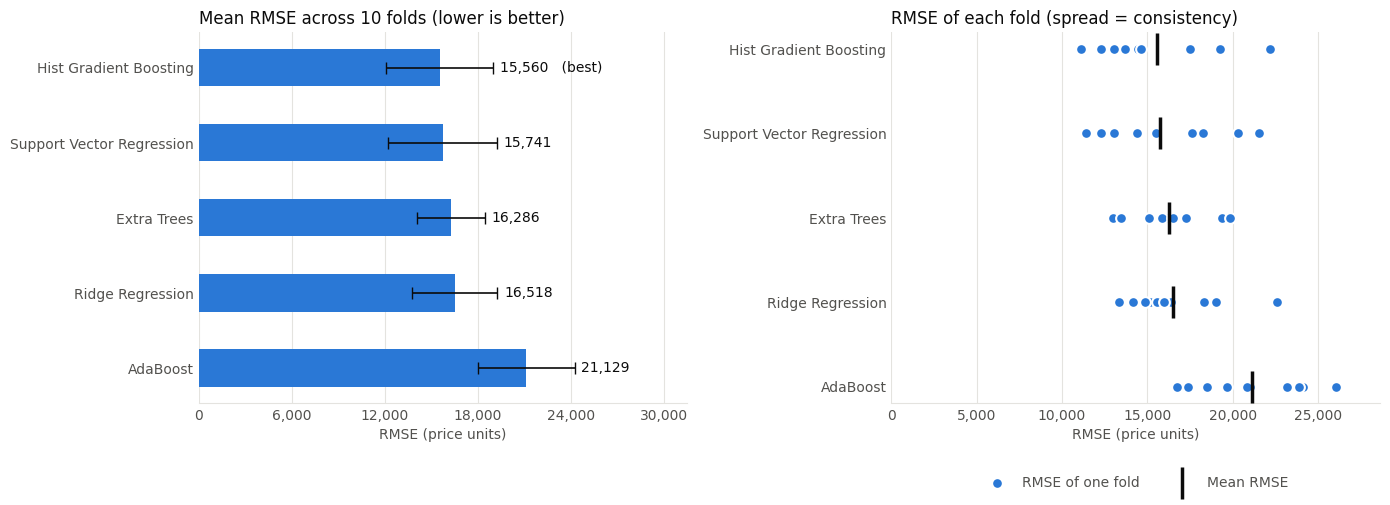

In [15]:
# Chart colours: one blue for the data, dark/grey text, light grid
BAR_COLOR = "#2a78d6"
TEXT_COLOR = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID_COLOR = "#e4e3df"
numbers = FuncFormatter(lambda value, _: f"{value:,.0f}")

def style_axis(ax):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.xaxis.set_major_formatter(numbers)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

order = summary.index.tolist()            # best algorithm first
positions = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# ---- Chart 1: mean RMSE with +/- 1 std ----
means = summary["Mean RMSE"]
stds = summary["Std RMSE"]
ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    label = f"{means[name]:,.0f}" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + means.max() * 0.02, i, label,
             va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, (means + stds).max() * 1.3)
style_axis(ax1)
ax1.set_title("Mean RMSE across 10 folds (lower is better)", loc="left", color=TEXT_COLOR, fontsize=12)
ax1.set_xlabel("RMSE (price units)", color=MUTED_TEXT)

# ---- Chart 2: RMSE of every fold ----
for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=60, color=BAR_COLOR,
                edgecolor="white", linewidth=1.5, zorder=3,
                label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(means[name], i, marker="|", s=500, color=TEXT_COLOR, linewidth=2.5, zorder=4,
                label="Mean RMSE" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
ax2.set_xlim(0, per_fold_table.values.max() * 1.1)
style_axis(ax2)
ax2.set_title("RMSE of each fold (spread = consistency)", loc="left", color=TEXT_COLOR, fontsize=12)
ax2.set_xlabel("RMSE (price units)", color=MUTED_TEXT)
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, labelcolor=MUTED_TEXT)

plt.tight_layout()
plt.show()

## Step 9.4: Observations

> The numbers below come from our run. If your library versions are different, your numbers may differ slightly, but the overall pattern should be the same.

1. **Hist Gradient Boosting has the lowest mean RMSE (≈ 15,560, about 26% of the average price)**, but the top four algorithms are very close: SVR (≈ 15,740), Extra Trees (≈ 16,290) and Ridge (≈ 16,520). The gap between first and fourth (≈ 960) is much smaller than the standard deviation of each algorithm (≈ 2,200 – 3,500), so in practice these four are **tied**.
2. **AdaBoost is clearly the weakest** (≈ 21,130, about 35% of the average price). It has the highest RMSE on **every one of the 10 folds** (Step 9.1).
3. **The simple linear model (Ridge) is surprisingly competitive.** Unlike the car data, laptop prices depend fairly smoothly on RAM, SSD size, screen size and the brand/type, and these features, once cleaned in Step 4, work well in a linear model. Ridge even wins 3 of the 10 folds (Hist Gradient Boosting and SVR also win 3 each, Extra Trees wins 1), so **no single algorithm wins every fold**.
4. **The result depends on the fold.** Fold 2 contains the most expensive laptop in the dataset (≈ 325,000) and Hist Gradient Boosting has its worst fold there (≈ 22,200), while Ridge is much better on that fold (≈ 15,100). Fold 3 is the easiest fold for all five algorithms (Hist Gradient Boosting ≈ 11,100), and Fold 1 is hard for all of them (≈ 18,000 – 24,000). This is why we average over 10 folds instead of trusting one split.
5. **Consistency:** Extra Trees has the smallest standard deviation (≈ 2,200), so it is the most consistent, even though its mean RMSE is not the lowest.
6. **Accuracy vs. speed:** Ridge and SVR train in about 2 seconds or less for all 10 folds, while Extra Trees and Hist Gradient Boosting take several times longer (about 10 seconds or more), for almost the same RMSE. In a real project this trade-off matters.
7. **The error is still large (≈ 26% of the average price).** The model only sees the specifications in the dataset. It cannot know about things such as the exact model name or build quality, which also affect the price.

# Step 10: Train the Final Model
## Step 10.1: Select the Best Algorithm

**Cross validation is used to *choose* an algorithm, not to produce the final model.** The 10 models built during cross validation were only used to measure performance and are now thrown away.

We select the algorithm with the **lowest mean RMSE** from the summary table.

In [16]:
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE"]

print(f"Best algorithm : {best_algorithm_name}")
print(f"Expected RMSE  : {best_mean_rmse:,.2f} (+/- {best_std_rmse:,.2f})")

Best algorithm : Hist Gradient Boosting
Expected RMSE  : 15,560.32 (+/- 3,450.50)


## Step 10.2: Train the Best Algorithm on All the Data

Now that we know which algorithm works best, we train it on **all laptops**. There is no separate test set here, because the cross-validation RMSE from Step 9 is already our estimate of how well this model will perform on new, unseen laptops.

In [17]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", algorithms[best_algorithm_name]),
])

final_model.fit(X, y)

print(f"Final {best_algorithm_name} model trained on {len(X):,} laptops.")

Final Hist Gradient Boosting model trained on 1,274 laptops.


## Step 10.3: Save the Trained Model

The saved file contains the **whole pipeline** (imputer, scaler, one-hot encoder **and** the algorithm), so it can predict directly from raw laptop specifications.

We also save a small `.json` file with the best algorithm's name and its cross-validation RMSE. The Streamlit web app (`app.py`) uses both files for deployment.

To download the files to your computer in Colab, set `DOWNLOAD_MODEL = True` and run the cell again, or use the **Files** panel (folder icon) on the left.

In [18]:
MODEL_FILE = "laptop_price_model_full_dataset.pkl"
INFO_FILE = "laptop_model_info.json"
DOWNLOAD_MODEL = False

with open(MODEL_FILE, "wb") as f:
    pickle.dump(final_model, f)

# Small info file used by the web app (best algorithm, typical error, library version)
with open(INFO_FILE, "w") as f:
    json.dump({"best_algorithm": best_algorithm_name,
               "cv_rmse": round(float(best_mean_rmse), 2),
               "avg_price": round(float(average_price), 2),
               "sklearn_version": sklearn.__version__}, f)

print(f"Trained model saved as '{MODEL_FILE}'")
print(f"Model info saved as '{INFO_FILE}'")

if IN_COLAB and DOWNLOAD_MODEL:
    files.download(MODEL_FILE)
    files.download(INFO_FILE)

Trained model saved as 'laptop_price_model_full_dataset.pkl'
Model info saved as 'laptop_model_info.json'


# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example laptop below, so that **Run all** works without stopping. To type in your own laptop, set `USE_INTERACTIVE_INPUT = True` and run the cell again.

In [19]:
USE_INTERACTIVE_INPUT = False

example_laptop = {
    "Inches": 15.6,
    "Ram": 8,
    "Weight": 1.9,
    "SSD_GB": 256,
    "HDD_GB": 0,
    "Company": "Dell",
    "TypeName": "Notebook",
    "ScreenResolution": "Full HD 1920x1080",
    "Cpu": "Intel Core i5 7200U 2.5GHz",
    "Gpu": "Intel HD Graphics 620",
    "OpSys": "Windows 10",
}

def get_laptop_input():
    print("Enter Laptop Specifications (ranges seen in the data are shown):")
    print(f"  Inches : {X['Inches'].min()} - {X['Inches'].max()}")
    print(f"  Ram    : {X['Ram'].min()} - {X['Ram'].max()} (GB)")
    print(f"  Weight : {X['Weight'].min()} - {X['Weight'].max()} (kg)")
    print(f"  SSD_GB : {X['SSD_GB'].min():.0f} - {X['SSD_GB'].max():.0f}")
    print(f"  HDD_GB : {X['HDD_GB'].min():.0f} - {X['HDD_GB'].max():.0f}")

    laptop = {
        "Inches": float(input("Inches: ")),
        "Ram": int(input("Ram (GB): ")),
        "Weight": float(input("Weight (kg): ")),
        "SSD_GB": float(input("SSD_GB: ")),
        "HDD_GB": float(input("HDD_GB: ")),
    }
    print("\nAvailable Companies:", sorted(X["Company"].unique()))
    laptop["Company"] = input("Company: ").strip()
    print("\nAvailable Types:", sorted(X["TypeName"].unique()))
    laptop["TypeName"] = input("TypeName: ").strip()
    print("\nCommon Screen Resolutions:", X["ScreenResolution"].value_counts().index[:6].tolist())
    laptop["ScreenResolution"] = input("ScreenResolution: ").strip()
    print("\nCommon CPUs:", X["Cpu"].value_counts().index[:6].tolist())
    laptop["Cpu"] = input("Cpu: ").strip()
    print("\nCommon GPUs:", X["Gpu"].value_counts().index[:6].tolist())
    laptop["Gpu"] = input("Gpu: ").strip()
    print("\nAvailable Operating Systems:", sorted(X["OpSys"].unique()))
    laptop["OpSys"] = input("OpSys: ").strip()
    return laptop

user_input = get_laptop_input() if USE_INTERACTIVE_INPUT else example_laptop

print("Laptop specifications:")
for feature, value in user_input.items():
    print(f"  {feature:<17}: {value}")

Laptop specifications:
  Inches           : 15.6
  Ram              : 8
  Weight           : 1.9
  SSD_GB           : 256
  HDD_GB           : 0
  Company          : Dell
  TypeName         : Notebook
  ScreenResolution : Full HD 1920x1080
  Cpu              : Intel Core i5 7200U 2.5GHz
  Gpu              : Intel HD Graphics 620
  OpSys            : Windows 10


## Step 11.2: Convert User Input into Feature Vector

The feature vector must have **exactly the same columns, in the same order,** as the training data. There is no need to encode it manually: the saved pipeline scales and one-hot encodes it automatically.

In [20]:
feature_vector = pd.DataFrame([user_input])[numeric_features + categorical_features]
feature_vector

,Inches,Ram,Weight,SSD_GB,HDD_GB,Company,TypeName,ScreenResolution,Cpu,Gpu,OpSys
0,15.60,8,1.90,256,0,Dell,Notebook,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,Intel HD Graphics 620,Windows 10


## Step 11.3: Load the Saved Model

In [21]:
with open(MODEL_FILE, "rb") as f:
    loaded_model = pickle.load(f)

print(f"Model loaded from '{MODEL_FILE}': {loaded_model.named_steps['regressor'].regressor_.__class__.__name__}")

Model loaded from 'laptop_price_model_full_dataset.pkl': HistGradientBoostingRegressor


## Step 11.4: Model Prediction

Apply the model to the feature vector of the unseen laptop and return the prediction to the user.

In [22]:
predicted_price = loaded_model.predict(feature_vector)[0]

print(f"Predicted Price: {predicted_price:,.2f}")
print(f"Typical error (cross-validation RMSE of {best_algorithm_name}): about {best_mean_rmse:,.0f}")

Predicted Price: 54,837.62
Typical error (cross-validation RMSE of Hist Gradient Boosting): about 15,560


# Step 12: Execute the Feedback Phase

After deployment, feedback from users and domain experts (e.g. laptop sellers) is used to improve the model. Potential improvements for this system:

1. **Extract more information from the text columns**: the processor series (i3/i5/i7), the processor speed in GHz, the graphics brand, and whether the screen is IPS or touchscreen are all hidden inside the text columns and strongly affect price. In an earlier quick test, adding these as extra features gave a small improvement.
2. **Tune hyper-parameters**: e.g. `C` in SVR, `alpha` in Ridge, or the number of trees. Use cross validation (`GridSearchCV`) to choose them.
3. **Keep prices up to date**: laptop prices change quickly. The dataset should be refreshed regularly and the model re-trained.
4. **Report an error measure that is less sensitive to outliers** (e.g. MAE) alongside RMSE.

# Conclusion

In this notebook we compared **5 regression algorithms** (none of them used in the Car Price system) on the **full laptop price dataset (1,274 unique laptops)** using **10-fold cross validation** and **RMSE**.

- **Hist Gradient Boosting** achieved the lowest mean RMSE (≈ 15,560, about 26% of the average price). **SVR, Extra Trees and Ridge Regression** were very close behind, so the top four are effectively tied. Hist Gradient Boosting was trained on all the laptops, saved, and used to predict the price of a new laptop.
- **AdaBoost performed worst** (≈ 21,130).
- Unlike the car data, a **simple linear model (Ridge) is competitive** on this dataset, and it is much faster than the tree ensembles.
- Training on the **log of the price** was important for SVR (and AdaBoost); without it, SVR's RMSE was more than twice as large.
- RMSE varies from fold to fold, mainly depending on how many very expensive laptops are in the test fold, which is why cross validation gives a more reliable comparison than a single split.